# 01 Data Exploration and Molecular Statistics

This notebook performs molecular dataset exploration for the QCBM Molecular Augmentation project.

Main tasks:

- Load processed Parquet datasets
- Inspect dataset sizes and schemas
- Compute molecular descriptors
- Analyze molecular weight, LogP, TPSA, HBD, HBA, ring count, heavy atom count
- Compute validity, uniqueness, and novelty
- Compute QED, SA Score, and SYBA
- Analyze Morgan fingerprint diversity
- Analyze Murcko scaffolds
- Analyze BRICS fragments
- Save EDA outputs for downstream notebooks

In [1]:
import warnings

warnings.filterwarnings("ignore")

import os

import numpy as np
import pandas as pd

import dask.dataframe as dd

from rdkit import Chem


In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(SRC_DIR)
    )

print("PROJECT_ROOT =", PROJECT_ROOT)
print("SRC_DIR =", SRC_DIR)

PROJECT_ROOT = d:\QCBM Molecular Augmentation Lite
SRC_DIR = d:\QCBM Molecular Augmentation Lite\src


In [4]:
import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rdkit import Chem
from rdkit import RDLogger

RDLogger.DisableLog("rdApp.*")

from molaug_qcbm.preprocessing.descriptors import (
    descriptor_dataframe,
    descriptor_summary
)

from molaug_qcbm.preprocessing.fingerprints import (
    batch_fingerprints,
    average_diversity,
    fingerprint_similarity_matrix
)

from molaug_qcbm.evaluation.validity import (
    validity_report,
    valid_molecules
)

from molaug_qcbm.evaluation.uniqueness import (
    uniqueness_report,
    duplicate_molecules
)

from molaug_qcbm.evaluation.novelty import (
    novelty_report
)

from molaug_qcbm.evaluation.qed import (
    qed_score,
    qed_report,
    qed_dataframe,
    top_qed_molecules
)

from molaug_qcbm.evaluation.sa_score import (
    sa_score,
    sa_report,
    sa_dataframe,
    easiest_molecules,
    hardest_molecules
)

from molaug_qcbm.evaluation.syba import (
    syba_score_smiles,
    syba_report
)

from molaug_qcbm.encoding.scaffold_encoding import (
    ScaffoldEncoder
)

from molaug_qcbm.encoding.fragment_encoding import (
    FragmentEncoder
)

print("Imports successful.")

Imports successful.


In [5]:
PROJECT_ROOT = r"D:\QCBM Molecular Augmentation Lite"

PROCESSED_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed"
)

BENCHMARK_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "benchmark_splits"
)

EMBEDDINGS_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "embeddings"
)

EDA_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "eda"
)

os.makedirs(
    EDA_DIR,
    exist_ok=True
)

STONED_PARQUET = os.path.join(
    PROCESSED_DIR,
    "stoned_1m.parquet"
)

KNOWN_PARQUET = os.path.join(
    PROCESSED_DIR,
    "known_inhibitors.parquet"
)

KRAS_PARQUET = os.path.join(
    PROCESSED_DIR,
    "kras_activity.parquet"
)

TRAIN_PARQUET = os.path.join(
    BENCHMARK_DIR,
    "train.parquet"
)

VALIDATION_PARQUET = os.path.join(
    BENCHMARK_DIR,
    "validation.parquet"
)

TEST_PARQUET = os.path.join(
    BENCHMARK_DIR,
    "test.parquet"
)

In [6]:
stoned_df = pd.read_parquet(
    STONED_PARQUET
)

known_df = pd.read_parquet(
    KNOWN_PARQUET
)

kras_df = pd.read_parquet(
    KRAS_PARQUET
)

train_df = pd.read_parquet(
    TRAIN_PARQUET
)

validation_df = pd.read_parquet(
    VALIDATION_PARQUET
)

test_df = pd.read_parquet(
    TEST_PARQUET
)

print("STONED:", stoned_df.shape)
print("Known inhibitors:", known_df.shape)
print("KRAS:", kras_df.shape)
print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

STONED: (1010510, 2)
Known inhibitors: (636, 6)
KRAS: (645, 5)
Train: (808408, 2)
Validation: (101051, 2)
Test: (101051, 2)


In [7]:
dataset_overview = pd.DataFrame(
    {
        "Dataset": [
            "STONED 1M",
            "Known Inhibitors",
            "KRAS Activity",
            "Train",
            "Validation",
            "Test"
        ],
        "Rows": [
            len(stoned_df),
            len(known_df),
            len(kras_df),
            len(train_df),
            len(validation_df),
            len(test_df)
        ],
        "Columns": [
            len(stoned_df.columns),
            len(known_df.columns),
            len(kras_df.columns),
            len(train_df.columns),
            len(validation_df.columns),
            len(test_df.columns)
        ]
    }
)

dataset_overview

,Dataset,Rows,Columns
0,STONED 1M,1010510,2
1,Known Inhibitors,636,6
2,KRAS Activity,645,5
3,Train,808408,2
4,Validation,101051,2
5,Test,101051,2


In [8]:
print("STONED columns:")
print(stoned_df.columns.tolist())

print("\nKnown inhibitors columns:")
print(known_df.columns.tolist())

print("\nKRAS columns:")
print(kras_df.columns.tolist())

print("\nTrain columns:")
print(train_df.columns.tolist())

STONED columns:
['id', 'smiles']

Known inhibitors columns:
['id', 'smiles', 'KRAS G12D SPR KD  (nM)', 'KRAS G12D binding IC50 (nM)', 'pERK IC50 (nM)', 'selfies']

KRAS columns:
['id', 'smiles', 'KRAS G12D SPR KD  (nM)', 'KRAS G12D binding IC50 (nM)', 'pERK IC50 (nM)']

Train columns:
['id', 'smiles']


In [9]:
stoned_df.head()

,id,smiles
__null_dask_index__,,
0,0,CC1=C(CNc2cccnc2C)CN(C)C1OCCCCCN
1,1,CCN1CCCC1Cc1nc2c(c(N(C)CCCNC)n1)CCN(c1cncc3ccc...
2,2,C1=CCC(CCOc2nc3c([nH]2)CCN(c2ccccc2)C3)CC1
3,3,C=CC1(Oc2nc(N3CCN(CC)CC3)c3cnc(-c4ccccc4NC)c(F...
4,4,C=CNC(C)CCOc1nc(CN2CCNCC2)c2cnc(-c3ccccc3C(F)(...


In [10]:
known_df.head()

,id,smiles,KRAS G12D SPR KD (nM),KRAS G12D binding IC50 (nM),pERK IC50 (nM),selfies
0,1,CN1[C@H](COc2nc3cc(-c4cc(O)cc5ccccc45)ncc3c(N3...,97.7,124.7,3159.1,[C][N][C@H1][Branch2][Branch1][=Branch1][C][O]...
1,2,CN1[C@H](COc2nc(N3CC(CC4)NC4C3)c(cnc(-c3cc(O)c...,2.4,2.7,721.4,[C][N][C@H1][Branch2][Branch1][#Branch2][C][O]...
2,3,Cn1c(CCOc2nc(N3CC(CC4)NC4C3)c(cnc(-c3cc(O)cc4c...,8.3,9.5,10283.1,[C][N][C][Branch2][Branch1][O][C][C][O][C][=N]...
3,4,Oc1cc2ccccc2c(-c(ncc(c2n3)c(N4CC(CC5)NC5C4)nc3...,155.7,496.2,8530,[O][C][=C][C][=C][C][=C][C][=C][Ring1][=Branch...
4,5,Cn1nccc1COc1nc(N2CC(CC3)NC3C2)c(cnc(-c2cc(O)cc...,294.8,722.9,8193.8,[C][N][N][=C][C][=C][Ring1][Branch1][C][O][C][...


In [11]:
kras_df.head()

,id,smiles,KRAS G12D SPR KD (nM),KRAS G12D binding IC50 (nM),pERK IC50 (nM)
0,1,CN1[C@H](COc2nc3cc(-c4cc(O)cc5ccccc45)ncc3c(N3...,97.7,124.7,3159.1
1,2,CN1[C@H](COc2nc(N3CC(CC4)NC4C3)c(cnc(-c3cc(O)c...,2.4,2.7,721.4
2,3,Cn1c(CCOc2nc(N3CC(CC4)NC4C3)c(cnc(-c3cc(O)cc4c...,8.3,9.5,10283.1
3,4,Oc1cc2ccccc2c(-c(ncc(c2n3)c(N4CC(CC5)NC5C4)nc3...,155.7,496.2,8530
4,5,Cn1nccc1COc1nc(N2CC(CC3)NC3C2)c(cnc(-c2cc(O)cc...,294.8,722.9,8193.8


In [12]:
stoned_smiles = (
    stoned_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

known_smiles = (
    known_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

kras_smiles = (
    kras_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

train_smiles = (
    train_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

validation_smiles = (
    validation_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

test_smiles = (
    test_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

print("STONED:", len(stoned_smiles))
print("Known:", len(known_smiles))
print("KRAS:", len(kras_smiles))
print("Train:", len(train_smiles))
print("Validation:", len(validation_smiles))
print("Test:", len(test_smiles))

STONED: 1010510
Known: 636
KRAS: 645
Train: 808408
Validation: 101051
Test: 101051


In [13]:
EDA_SAMPLE_SIZE = 20000

eda_sample_df = train_df.sample(
    n=min(
        EDA_SAMPLE_SIZE,
        len(train_df)
    ),
    random_state=42
).reset_index(
    drop=True
)

eda_smiles = (
    eda_sample_df["smiles"]
    .dropna()
    .astype(str)
    .tolist()
)

print("EDA sample size:", len(eda_smiles))

EDA sample size: 20000


In [14]:
validity_table = pd.DataFrame(
    [
        {
            "Dataset": "STONED Sample",
            **validity_report(eda_smiles)
        },
        {
            "Dataset": "Known Inhibitors",
            **validity_report(known_smiles)
        },
        {
            "Dataset": "KRAS",
            **validity_report(kras_smiles)
        }
    ]
)

validity_table

,Dataset,total,valid,invalid,validity,validity_percent
0,STONED Sample,20000,19999,1,0.999950,99.995000
1,Known Inhibitors,636,636,0,1.000000,100.000000
2,KRAS,645,638,7,0.989147,98.914729


In [15]:
uniqueness_table = pd.DataFrame(
    [
        {
            "Dataset": "STONED Sample",
            **uniqueness_report(eda_smiles)
        },
        {
            "Dataset": "Known Inhibitors",
            **uniqueness_report(known_smiles)
        },
        {
            "Dataset": "KRAS",
            **uniqueness_report(kras_smiles)
        }
    ]
)

uniqueness_table

,Dataset,total,unique,duplicates,uniqueness,uniqueness_percent
0,STONED Sample,20000,19999,1,0.999950,99.995000
1,Known Inhibitors,636,629,7,0.988994,98.899371
2,KRAS,645,631,14,0.978295,97.829457


In [16]:
novelty_table = pd.DataFrame(
    [
        {
            "Generated Dataset": "STONED Sample",
            "Reference Dataset": "Known Inhibitors",
            **novelty_report(
                eda_smiles,
                known_smiles
            )
        },
        {
            "Generated Dataset": "STONED Sample",
            "Reference Dataset": "KRAS",
            **novelty_report(
                eda_smiles,
                kras_smiles
            )
        },
        {
            "Generated Dataset": "KRAS",
            "Reference Dataset": "Known Inhibitors",
            **novelty_report(
                kras_smiles,
                known_smiles
            )
        }
    ]
)

novelty_table

,Generated Dataset,Reference Dataset,generated,novel,seen,novelty,novelty_percent
0,STONED Sample,Known Inhibitors,20000,19987,12,0.999350,99.935000
1,STONED Sample,KRAS,20000,19987,12,0.999350,99.935000
2,KRAS,Known Inhibitors,645,2,636,0.003101,0.310078


In [17]:
known_duplicates = duplicate_molecules(
    known_smiles
)

print("Duplicate molecules in known inhibitors:", len(known_duplicates))

list(
    known_duplicates.items()
)[:10]

Duplicate molecules in known inhibitors: 7


[('Oc1cc(-c2ncc3c(N4CC5CCC(C4)N5)nc(OC[C@]45CCCN4C[C@@H](F)C5)nc3c2F)c2ccccc2c1',
  2),
 ('Oc1cc(-c2ncc3c(N4CC5CCC(C4)N5)nc(OC[C@@]45CCCN4C[C@H](F)C5)nc3c2F)c2c(Cl)cccc2c1',
  2),
 ('Oc1cc(-c2ncc3c(N4CC5CCC(C4)N5)nc(OC[C@@]45CCCN4C[C@H](F)C5)nc3c2F)c2c(F)cccc2c1',
  2),
 ('CCc1cccc2cncc(-c3ncc4c(N5CC6CCC(C5)N6)nc(OC[C@@]56CCCN5C[C@H](F)C6)nc4c3F)c12',
  2),
 ('Fc1c(-c2ccccc2C2CC2)ncc2c(N3CC4CCC(C3)N4)nc(OC[C@@]34CCCN3C[C@H](F)C4)nc12',
  2),
 ('C#Cc1cccc2cc(O)cc(-c3c(F)cc4c(N5CC6CCC(C5)N6)nc(OCC5(CN6CC7CC6CO7)CC5)nc4c3F)c12',
  2),
 ('CCCC1CC2CN(c3nc(OC[C@@H]4CCCN4C)nc4c3CCN(c3cccc5cccc(Cl)c35)C4)CC1N2', 2)]

In [18]:
descriptor_df = descriptor_dataframe(
    eda_smiles
)

descriptor_df.head()

,SMILES,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,RingCount,HeavyAtoms
0,CC(C)c1ccccc1N1Cc2cnc(OCC3CCCNN3C)nc2C1,367.497,3.09780,1.0,6.0,53.52,5.0,4.0,27.0
1,CCCC1CCCN(c2nc(OCC3CCCN3)nc3c2CCN(c2cncc4cnc(F...,505.642,4.26890,1.0,8.0,79.30,7.0,6.0,37.0
2,CCc1c(CN2CC(=O)C(C)(CO)C2)nc(CCc2ccccc2)n1C,355.482,2.15100,1.0,5.0,58.36,7.0,3.0,26.0
3,CCN(Cc1nc(OCC2CCCN2)[nH]c1N)c1ccccc1CNC,358.490,1.86860,4.0,6.0,91.23,9.0,3.0,26.0
4,CCCN1CCCC1Cc1nc(N2CNC(CC)NC2C)c2cnc(-c3cccc(C)...,521.685,4.60362,2.0,8.0,78.44,8.0,5.0,38.0


In [19]:
descriptor_stats = descriptor_summary(
    eda_smiles
)

descriptor_stats

,count,mean,std,min,25%,50%,75%,max
MolWt,19999.0,422.213850,66.112237,300.3280,366.38700,422.5080,479.58000,649.7420
LogP,19999.0,3.620989,0.840369,-0.1809,3.09281,3.7162,4.26721,5.7106
HBD,19999.0,1.329466,0.948576,0.0000,1.00000,1.0000,2.00000,5.0000
HBA,19999.0,6.129656,1.489618,2.0000,5.00000,6.0000,7.00000,10.0000
TPSA,19999.0,68.141493,17.929212,16.1300,55.20000,66.9800,79.54000,145.2400
RotatableBonds,19999.0,6.716536,1.629561,1.0000,6.00000,7.0000,8.00000,9.0000
RingCount,19999.0,4.396520,1.177123,1.0000,4.00000,4.0000,5.00000,9.0000
HeavyAtoms,19999.0,30.424321,4.700124,17.0000,26.00000,30.0000,35.00000,48.0000


In [20]:
descriptor_output_path = os.path.join(
    EDA_DIR,
    "descriptor_sample.parquet"
)

descriptor_df.to_parquet(
    descriptor_output_path,
    index=False
)

descriptor_stats.to_csv(
    os.path.join(
        EDA_DIR,
        "descriptor_summary.csv"
    )
)

print("Saved:", descriptor_output_path)

Saved: D:\QCBM Molecular Augmentation Lite\data\eda\descriptor_sample.parquet


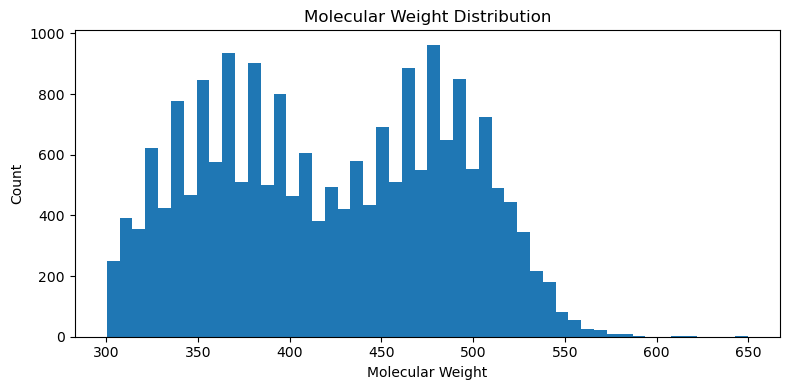

In [21]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    descriptor_df["MolWt"].dropna(),
    bins=50
)

plt.xlabel("Molecular Weight")
plt.ylabel("Count")
plt.title("Molecular Weight Distribution")
plt.tight_layout()
plt.show()

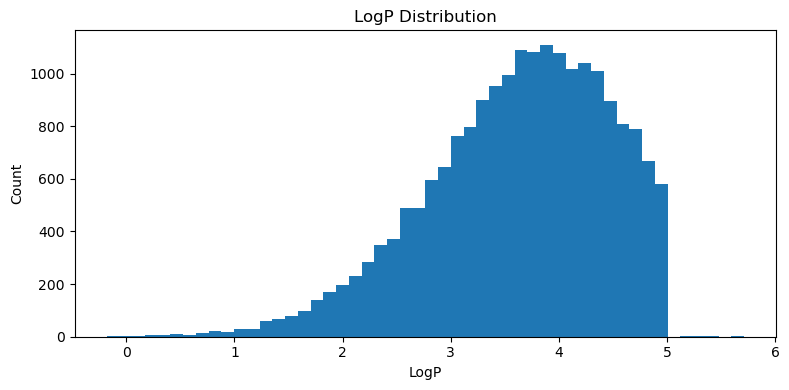

In [22]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    descriptor_df["LogP"].dropna(),
    bins=50
)

plt.xlabel("LogP")
plt.ylabel("Count")
plt.title("LogP Distribution")
plt.tight_layout()
plt.show()

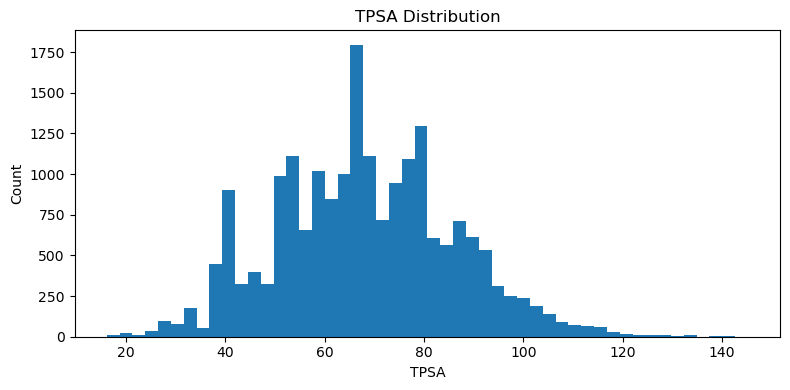

In [23]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    descriptor_df["TPSA"].dropna(),
    bins=50
)

plt.xlabel("TPSA")
plt.ylabel("Count")
plt.title("TPSA Distribution")
plt.tight_layout()
plt.show()

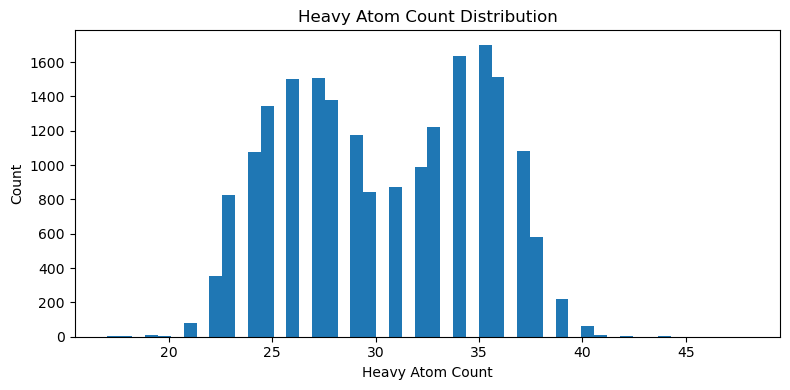

In [24]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    descriptor_df["HeavyAtoms"].dropna(),
    bins=50
)

plt.xlabel("Heavy Atom Count")
plt.ylabel("Count")
plt.title("Heavy Atom Count Distribution")
plt.tight_layout()
plt.show()

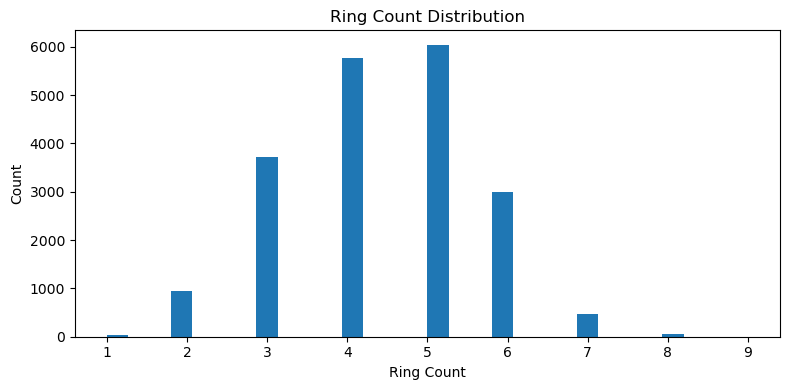

In [25]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    descriptor_df["RingCount"].dropna(),
    bins=30
)

plt.xlabel("Ring Count")
plt.ylabel("Count")
plt.title("Ring Count Distribution")
plt.tight_layout()
plt.show()

In [26]:
descriptor_numeric_cols = [
    "MolWt",
    "LogP",
    "HBD",
    "HBA",
    "TPSA",
    "RotatableBonds",
    "RingCount",
    "HeavyAtoms"
]

corr = descriptor_df[
    descriptor_numeric_cols
].corr()

corr

,MolWt,LogP,HBD,HBA,TPSA,RotatableBonds,RingCount,HeavyAtoms
MolWt,1.000000,0.389844,-0.005209,0.777086,0.396784,0.354401,0.732554,0.985384
LogP,0.389844,1.000000,-0.255331,-0.065358,-0.239006,0.151782,0.266238,0.379492
HBD,-0.005209,-0.255331,1.000000,0.122364,0.650980,0.203148,-0.055427,0.006440
HBA,0.777086,-0.065358,0.122364,1.000000,0.649517,0.311947,0.610876,0.787035
TPSA,0.396784,-0.239006,0.650980,0.649517,1.000000,0.264416,0.274724,0.421484
RotatableBonds,0.354401,0.151782,0.203148,0.311947,0.264416,1.000000,-0.083893,0.350182
RingCount,0.732554,0.266238,-0.055427,0.610876,0.274724,-0.083893,1.000000,0.778842
HeavyAtoms,0.985384,0.379492,0.006440,0.787035,0.421484,0.350182,0.778842,1.000000


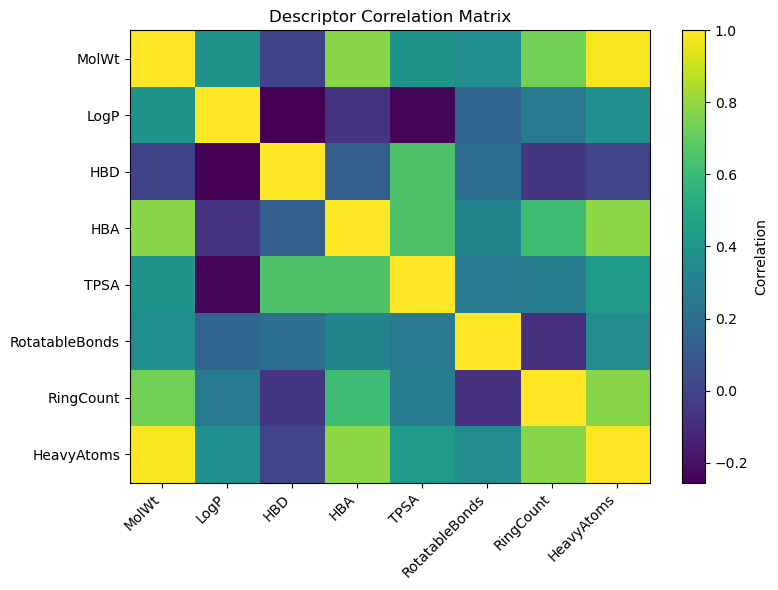

In [27]:
plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    corr,
    aspect="auto"
)

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(corr.index)),
    corr.index
)

plt.colorbar(
    label="Correlation"
)

plt.title("Descriptor Correlation Matrix")
plt.tight_layout()
plt.show()

In [28]:
qed_df = qed_dataframe(
    eda_smiles
)

qed_df.head()

,SMILES,QED
0,CC(C)c1ccccc1N1Cc2cnc(OCC3CCCNN3C)nc2C1,0.876415
1,CCCC1CCCN(c2nc(OCC3CCCN3)nc3c2CCN(c2cncc4cnc(F...,0.477239
2,CCc1c(CN2CC(=O)C(C)(CO)C2)nc(CCc2ccccc2)n1C,0.826787
3,CCN(Cc1nc(OCC2CCCN2)[nH]c1N)c1ccccc1CNC,0.547011
4,CCCN1CCCC1Cc1nc(N2CNC(CC)NC2C)c2cnc(-c3cccc(C)...,0.445321


In [29]:
qed_stats = qed_report(
    eda_smiles
)

qed_stats

{'n_molecules': 19999,
 'mean_qed': 0.5983216474201571,
 'median_qed': 0.5837560639441,
 'max_qed': 0.9474791584371645,
 'min_qed': 0.12029347411768125}

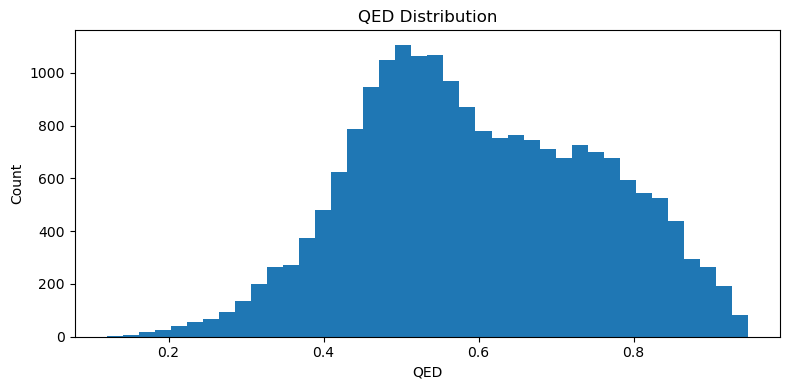

In [30]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    qed_df["QED"].dropna(),
    bins=40
)

plt.xlabel("QED")
plt.ylabel("Count")
plt.title("QED Distribution")
plt.tight_layout()
plt.show()

In [31]:
top_qed_df = top_qed_molecules(
    eda_smiles,
    top_k=20
)

top_qed_df

,SMILES,QED
0,Cc1cc(N2CC(CO)CC2=O)cnc1-c1ccccc1F,0.947479
1,C=C1C2=NC(OCC3CC3)=NC2CN1c1cccc2[nH]ncc12,0.947193
2,Cc1ncc(Cc2ccccc2F)c(C2CN(O)CC2C)n1,0.946724
3,CCCC1N(Cc2c(C)ccc3[nH]ncc23)C2=NN1C(C)CO2,0.942801
4,CC1CN(C)CC1Oc1ncc(O)c(-c2ccccc2F)n1,0.942734
5,CCN1Cc2nc(OCC3CCCN3C)ccc2-c2[nH]ccc21,0.942656
6,CC1=NCN(c2c(C)ccc3[nH]ncc23)CC1OCC1CCC1,0.942224
7,c1cnc2c(c1)CCN(c1ccccc1OCC1CCCN1)C2,0.942201
8,CCc1ccccc1N1CCc2cnc(C3CC=C3O)nc2C1,0.942163
9,CC1Cc2cnc(C3(CO)CCCC3)nc2CN1c1ccccc1,0.941973


In [32]:
sa_df = sa_dataframe(
    eda_smiles
)

sa_df.head()

,SMILES,SA_Score
0,CC(C)c1ccccc1N1Cc2cnc(OCC3CCCNN3C)nc2C1,3.504636
1,CCCC1CCCN(c2nc(OCC3CCCN3)nc3c2CCN(c2cncc4cnc(F...,4.010220
2,CCc1c(CN2CC(=O)C(C)(CO)C2)nc(CCc2ccccc2)n1C,3.404160
3,CCN(Cc1nc(OCC2CCCN2)[nH]c1N)c1ccccc1CNC,3.583358
4,CCCN1CCCC1Cc1nc(N2CNC(CC)NC2C)c2cnc(-c3cccc(C)...,4.503975


In [33]:
sa_stats = sa_report(
    eda_smiles
)

sa_stats

{'n_molecules': 19999,
 'mean_sa': 3.7792599484528737,
 'median_sa': 3.8044816906154324,
 'std_sa': 0.4409557468362064,
 'min_sa': 2.1929788561641796,
 'max_sa': 5.953006696142981}

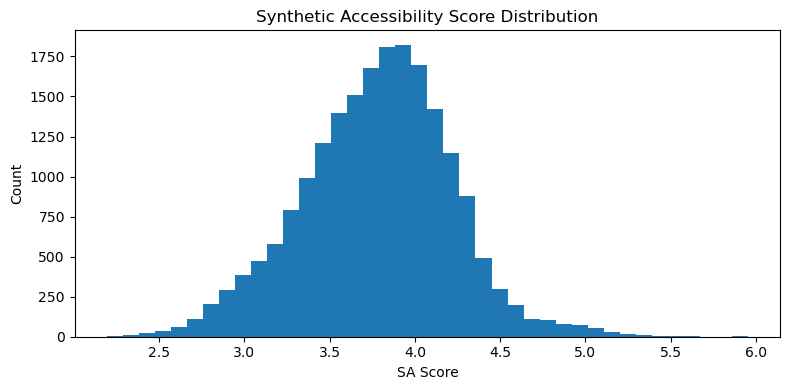

In [34]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    sa_df["SA_Score"].dropna(),
    bins=40
)

plt.xlabel("SA Score")
plt.ylabel("Count")
plt.title("Synthetic Accessibility Score Distribution")
plt.tight_layout()
plt.show()

In [35]:
easiest_molecules(
    eda_smiles,
    top_k=20
)

,SMILES,SA_Score
0,Clc1cccc2cncc(OCCCCN3CCCC3)c12,2.192979
1,CCCOc1ccc(CNc2cc(F)ccc2C(F)(F)F)cn1,2.230921
2,Cc1cc(CN2CCN(C)C2)cnc1-c1ccccc1Cl,2.306640
3,CCCCCOc1nccc(N(C)Cc2ccccc2CC)n1,2.321615
4,CC(C)Oc1ccccc1-c1ncc(CN2CCNCC2)cc1F,2.324497
5,CCOc1nc(NCCc2ccccc2F)c2cnccc2n1,2.330077
6,CN(CCCCc1ncccn1)CCNc1cc(F)ccc1F,2.345813
7,CC(C)COc1nccc(Nc2ccccc2C(F)(F)F)n1,2.349958
8,CCCCOc1cccc(CC)c1NCc1cccnc1CN,2.358958
9,c1ccc(CCN2CC(c3cnc(OCC4CCC4)nc3)C2)cc1,2.361163


In [36]:
hardest_molecules(
    eda_smiles,
    top_k=20
)

,SMILES,SA_Score
0,C#CC1=CC=CC2=CC(O)=CC(C3=C(C=C4C(N5CC6CCC(N6)C...,5.953007
1,Fc1c(Cc2cccc3[nH]ccc23)ncc(C2=NC34CN2CC3CO4)c1...,5.873025
2,CC(=CN(Cc1cc2nc(n1)C21C(C)CN1C)c1c(C)ccc2[nH]n...,5.702181
3,CCC1=CC=CC2=C1C(N1CCC3=C(C1)N=C(OCC14CCCN1C[C@...,5.636156
4,CCC(CC)COC1=NC23CCCN2CC1(CCN(C)c1cnnc2cccc(Cl)...,5.634241
5,CCC1CCN(C2=NN(OCC3CCCN3C)C3=CC2C(Nc2cncc4c(O)c...,5.521036
6,OC(C=CN1C2CCC1CN(c1nc(N3CC4(CCOCC4)C3)nc3c(F)c...,5.520151
7,CC1=CC2=CC(N1Cc1cnc(CC34CCCN3CCC4)nc1NC1CCCC1C...,5.499785
8,COCCN1CCC2(CC1)OC(N=c1cc(C)[nH]c(Cc3ccccc3Cl)c...,5.459908
9,COC1CC(COc2nc(N3CC4CCC(C3)N4)c3cnc(Cc4ccccc4C(...,5.398357


In [37]:
syba_scores = [
    syba_score_smiles(
        smiles
    )
    for smiles in eda_smiles
]

syba_df = pd.DataFrame(
    {
        "SMILES": eda_smiles,
        "SYBA": syba_scores
    }
)

syba_df.head()

,SMILES,SYBA
0,CC(C)c1ccccc1N1Cc2cnc(OCC3CCCNN3C)nc2C1,26.527433
1,CCCC1CCCN(c2nc(OCC3CCCN3)nc3c2CCN(c2cncc4cnc(F...,4.449827
2,CCc1c(CN2CC(=O)C(C)(CO)C2)nc(CCc2ccccc2)n1C,49.945103
3,CCN(Cc1nc(OCC2CCCN2)[nH]c1N)c1ccccc1CNC,10.924957
4,CCCN1CCCC1Cc1nc(N2CNC(CC)NC2C)c2cnc(-c3cccc(C)...,2.360156


In [38]:
syba_stats = syba_report(
    eda_smiles
)

syba_stats

{'n_molecules': 19999,
 'mean': 22.399208178105244,
 'std': 17.65132583706799,
 'min': -62.592962463244554,
 'max': 108.85998989427549,
 'median': 18.603901901353723}

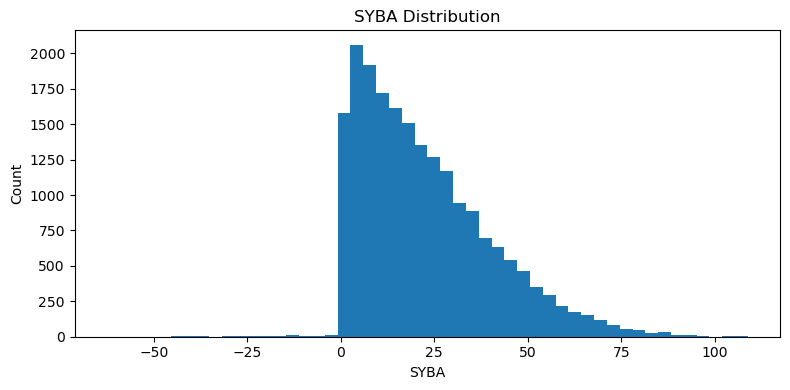

In [39]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    syba_df["SYBA"].dropna(),
    bins=50
)

plt.xlabel("SYBA")
plt.ylabel("Count")
plt.title("SYBA Distribution")
plt.tight_layout()
plt.show()

In [40]:
FP_SAMPLE_SIZE = 5000

fp_smiles = eda_smiles[
    :FP_SAMPLE_SIZE
]

fingerprint_matrix, valid_fp_smiles = batch_fingerprints(
    fp_smiles,
    radius=2,
    n_bits=2048
)

print("Fingerprint matrix shape:", fingerprint_matrix.shape)
print("Valid fingerprint molecules:", len(valid_fp_smiles))

Fingerprint matrix shape: (4999, 2048)
Valid fingerprint molecules: 4999


In [41]:
bit_density = fingerprint_matrix.mean(
    axis=0
)

print("Mean active bit density:", float(bit_density.mean()))
print("Max active bit density:", float(bit_density.max()))
print("Min active bit density:", float(bit_density.min()))

Mean active bit density: 0.030363006194989
Max active bit density: 1.0
Min active bit density: 0.00040008001600320064


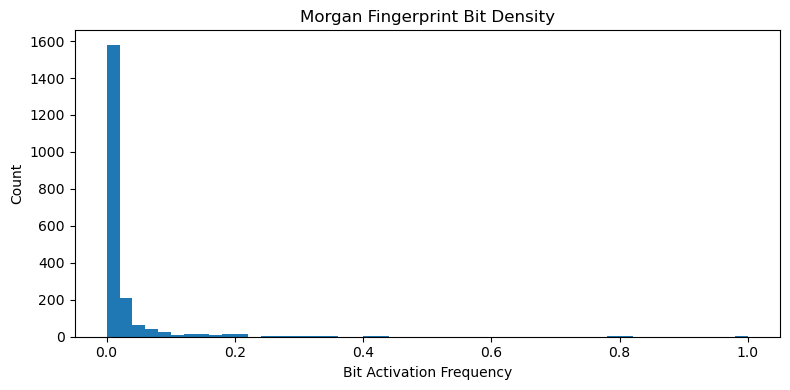

In [42]:
plt.figure(
    figsize=(8, 4)
)

plt.hist(
    bit_density,
    bins=50
)

plt.xlabel("Bit Activation Frequency")
plt.ylabel("Count")
plt.title("Morgan Fingerprint Bit Density")
plt.tight_layout()
plt.show()

In [43]:
DIVERSITY_SAMPLE_SIZE = 1000

diversity_score = average_diversity(
    valid_fp_smiles[:DIVERSITY_SAMPLE_SIZE]
)

print("Average molecular diversity:", diversity_score)

Average molecular diversity: 0.8239815994214089


In [44]:
SIMILARITY_SAMPLE_SIZE = 200

similarity_smiles = valid_fp_smiles[
    :SIMILARITY_SAMPLE_SIZE
]

similarity_matrix = fingerprint_similarity_matrix(
    similarity_smiles
)

similarity_matrix.shape

(200, 200)

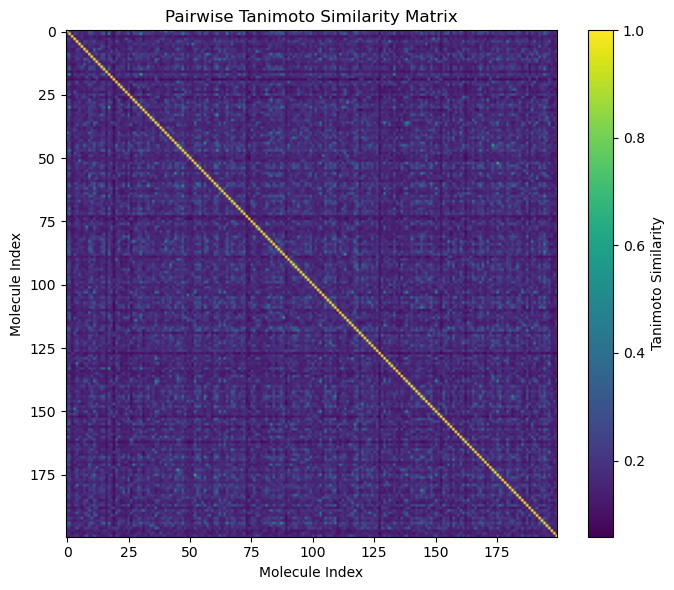

In [45]:
plt.figure(
    figsize=(7, 6)
)

plt.imshow(
    similarity_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Tanimoto Similarity"
)

plt.title("Pairwise Tanimoto Similarity Matrix")
plt.xlabel("Molecule Index")
plt.ylabel("Molecule Index")
plt.tight_layout()
plt.show()

In [46]:
scaffold_encoder = ScaffoldEncoder()

scaffold_encoder.fit(
    eda_smiles
)

scaffold_encoder.summary()

{'fitted': True, 'unique_scaffolds': 14387}

In [47]:
top_scaffolds_df = scaffold_encoder.top_scaffolds(
    eda_smiles,
    top_k=20
)

top_scaffolds_df

,Scaffold,Count
0,c1ccc(N2CCc3cncnc3C2)cc1,215
1,c1ccc(N2CCc3[nH]cnc3C2)cc1,122
2,c1ccc(-c2cc3nc(OCC45CCCN4CCC5)ncc3cn2)cc1,120
3,c1cnc(OCC2CCCN2)nc1,106
4,c1ccc(-c2cc3ncncc3cn2)cc1,90
5,c1ccc2c(N3CCc4cncnc4C3)cncc2c1,86
6,c1ccc(-c2cc3ncnc(N4CCN5CCC5C4)c3cn2)cc1,74
7,c1ncc2c(n1)CNCC2,70
8,c1ccc(-c2cc3nc(OCC4CCCN4)ncc3cn2)cc1,64
9,c1ccc2cnccc2c1,63


In [48]:
scaffold_df = scaffold_encoder.scaffold_dataframe(
    eda_smiles
)

scaffold_df.to_parquet(
    os.path.join(
        EDA_DIR,
        "scaffold_sample.parquet"
    ),
    index=False
)

top_scaffolds_df.to_csv(
    os.path.join(
        EDA_DIR,
        "top_scaffolds.csv"
    ),
    index=False
)

scaffold_df.head()

,SMILES,Scaffold
0,CC(C)c1ccccc1N1Cc2cnc(OCC3CCCNN3C)nc2C1,c1ccc(N2Cc3cnc(OCC4CCCNN4)nc3C2)cc1
1,CCCC1CCCN(c2nc(OCC3CCCN3)nc3c2CCN(c2cncc4cnc(F...,c1cc2c(N3CCc4c(nc(OCC5CCCN5)nc4N4CCCCC4)C3)cnc...
2,CCc1c(CN2CC(=O)C(C)(CO)C2)nc(CCc2ccccc2)n1C,O=C1CCN(Cc2c[nH]c(CCc3ccccc3)n2)C1
3,CCN(Cc1nc(OCC2CCCN2)[nH]c1N)c1ccccc1CNC,c1ccc(NCc2c[nH]c(OCC3CCCN3)n2)cc1
4,CCCN1CCCC1Cc1nc(N2CNC(CC)NC2C)c2cnc(-c3cccc(C)...,c1ccc(-c2cc3nc(CC4CCCN4)nc(N4CNCNC4)c3cn2)cc1


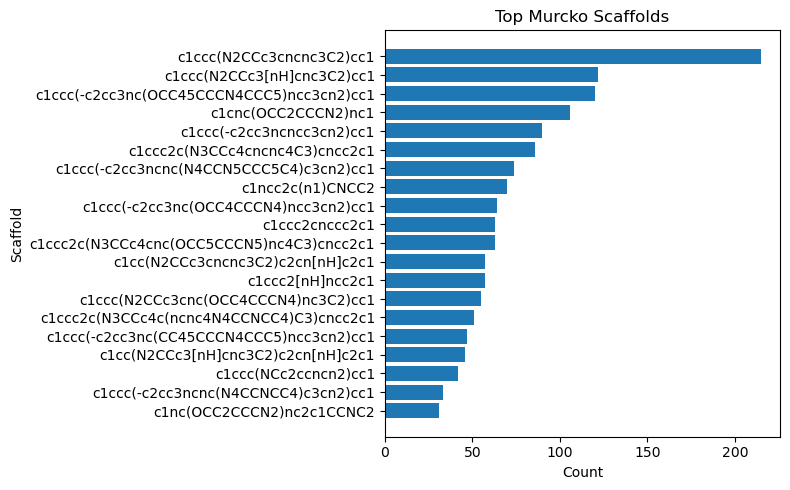

In [49]:
plt.figure(
    figsize=(8, 5)
)

plt.barh(
    top_scaffolds_df["Scaffold"].astype(str),
    top_scaffolds_df["Count"]
)

plt.xlabel("Count")
plt.ylabel("Scaffold")
plt.title("Top Murcko Scaffolds")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [50]:
fragment_encoder = FragmentEncoder()

fragment_encoder.fit(
    eda_smiles
)

fragment_encoder.summary()

{'fitted': True, 'unique_fragments': 10783}

In [51]:
top_fragments_df = fragment_encoder.top_fragments(
    eda_smiles,
    top_k=20
)

top_fragments_df

,Fragment,Count
0,[3*]O[3*],12694
1,[4*]C[8*],11650
2,[5*]N[5*],5534
3,[13*]C1CCCN1C,3802
4,[8*]CC,3004
5,[4*]CC,2536
6,[14*]c1nc([14*])c2cnc([14*])c(F)c2n1,2488
7,[5*]N([5*])C,2165
8,[16*]c1ccccc1[16*],2143
9,[8*]C[8*],2074


In [52]:
fragment_df = fragment_encoder.fragment_dataframe(
    eda_smiles
)

fragment_df.to_parquet(
    os.path.join(
        EDA_DIR,
        "fragment_sample.parquet"
    ),
    index=False
)

top_fragments_df.to_csv(
    os.path.join(
        EDA_DIR,
        "top_fragments.csv"
    ),
    index=False
)

fragment_df.head()

,SMILES,Fragments
0,CC(C)c1ccccc1N1Cc2cnc(OCC3CCCNN3C)nc2C1,"[[4*]C[8*], [8*]C(C)C, [3*]O[3*], [16*]c1ccccc..."
1,CCCC1CCCN(c2nc(OCC3CCCN3)nc3c2CCN(c2cncc4cnc(F...,"[[4*]C[8*], [5*]N1CCCC([15*])C1, [5*]N1CCc2c([..."
2,CCc1c(CN2CC(=O)C(C)(CO)C2)nc(CCc2ccccc2)n1C,"[[4*]C[8*], [8*]CO, [8*]CC, [5*]N1CC(=O)C([15*..."
3,CCN(Cc1nc(OCC2CCCN2)[nH]c1N)c1ccccc1CNC,"[[4*]CC, [4*]C[8*], [3*]O[3*], [5*]N([5*])[5*]..."
4,CCCN1CCCC1Cc1nc(N2CNC(CC)NC2C)c2cnc(-c3cccc(C)...,"[[3*]OC, [4*]CCC, [8*]C[8*], [14*]c1nc([14*])c..."


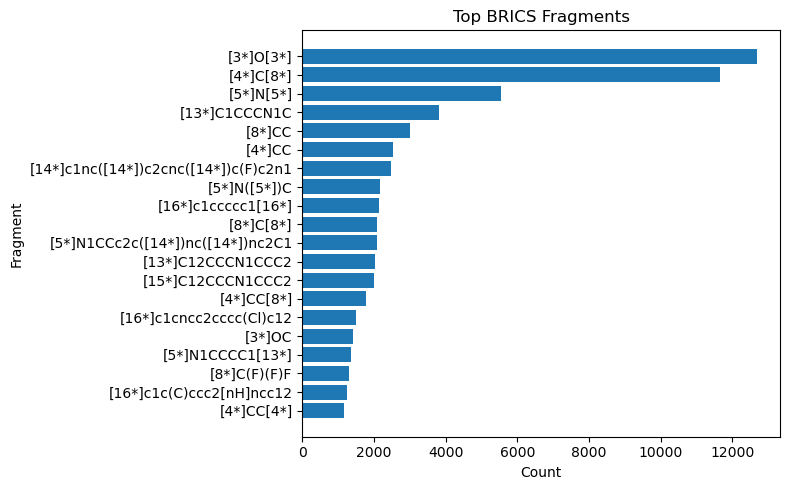

In [53]:
plt.figure(
    figsize=(8, 5)
)

plt.barh(
    top_fragments_df["Fragment"].astype(str),
    top_fragments_df["Count"]
)

plt.xlabel("Count")
plt.ylabel("Fragment")
plt.title("Top BRICS Fragments")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [54]:
activity_cols = [
    col
    for col in kras_df.columns
    if "nM" in col
]

activity_cols

['KRAS G12D SPR KD  (nM)', 'KRAS G12D binding IC50 (nM)', 'pERK IC50 (nM)']

In [55]:
kras_activity_summary = (
    kras_df[
        activity_cols
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
    .describe()
    .T
)

kras_activity_summary

,count,mean,std,min,25%,50%,75%,max
KRAS G12D SPR KD (nM),208.0,31407.881731,106547.157653,0.1,58.6,345.95,2379.55,666744.3
KRAS G12D binding IC50 (nM),609.0,758.984327,1657.418701,0.1,4.4,63.80,535.60,8846.4
pERK IC50 (nM),345.0,3354.173536,4063.145507,0.8,119.0,1616.50,5465.10,16314.3


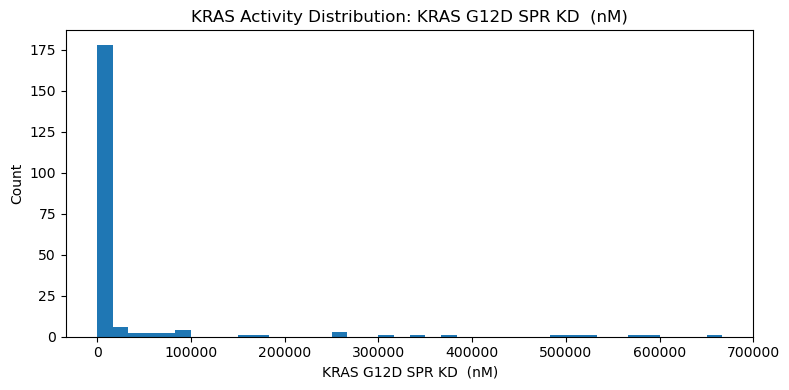

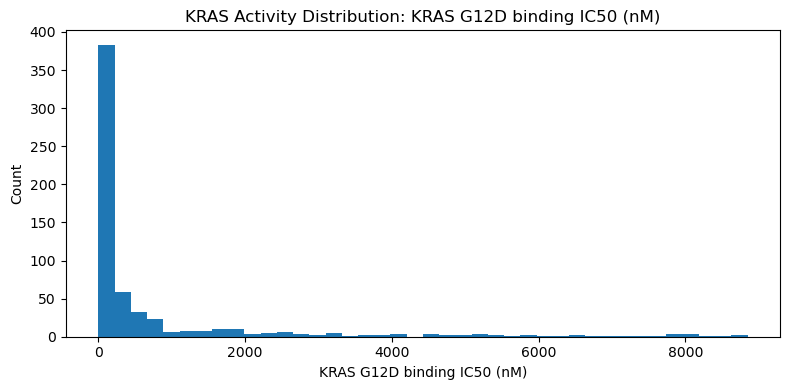

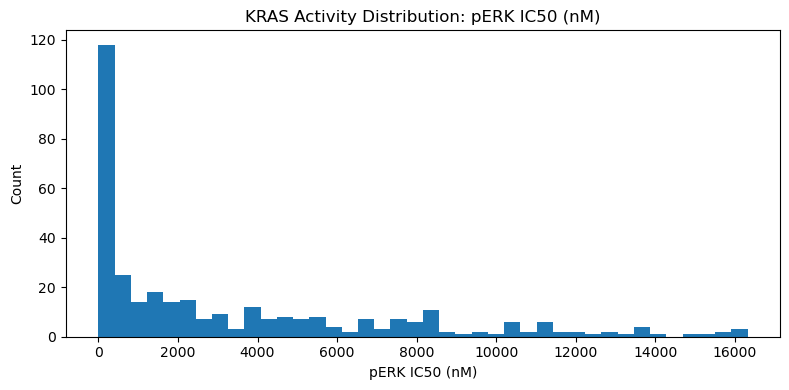

In [56]:
for col in activity_cols:

    values = pd.to_numeric(
        kras_df[col],
        errors="coerce"
    ).dropna()

    plt.figure(
        figsize=(8, 4)
    )

    plt.hist(
        values,
        bins=40
    )

    plt.xlabel(col)
    plt.ylabel("Count")
    plt.title(f"KRAS Activity Distribution: {col}")
    plt.tight_layout()
    plt.show()

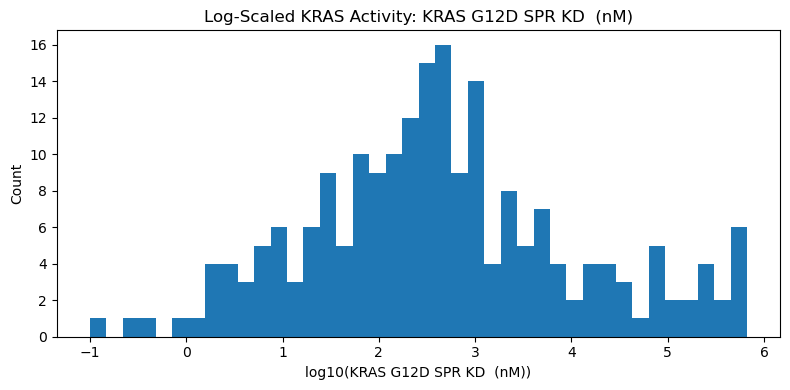

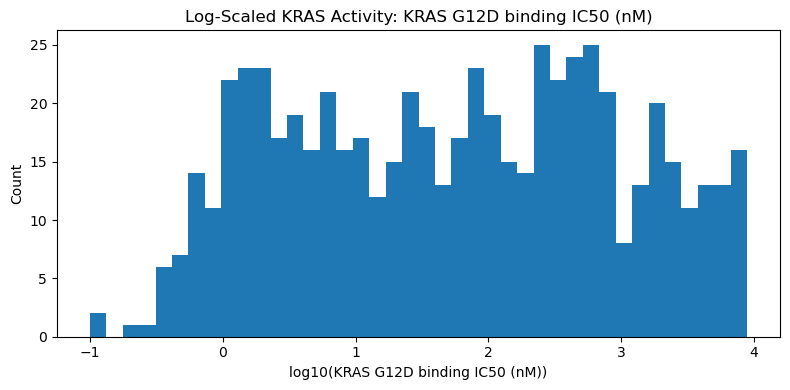

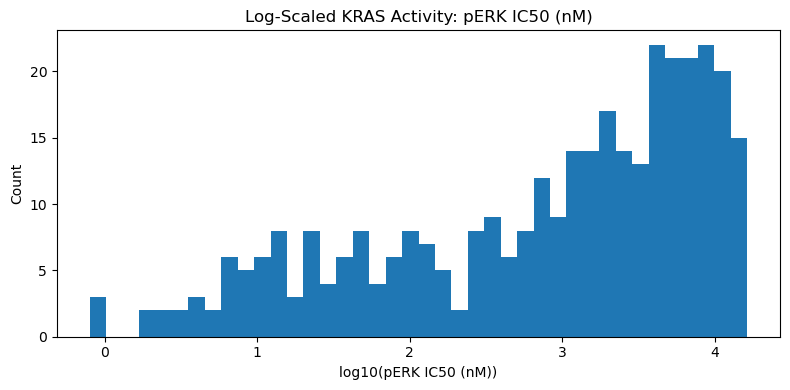

In [57]:
for col in activity_cols:

    values = pd.to_numeric(
        kras_df[col],
        errors="coerce"
    ).dropna()

    values = values[
        values > 0
    ]

    plt.figure(
        figsize=(8, 4)
    )

    plt.hist(
        np.log10(values),
        bins=40
    )

    plt.xlabel(f"log10({col})")
    plt.ylabel("Count")
    plt.title(f"Log-Scaled KRAS Activity: {col}")
    plt.tight_layout()
    plt.show()

In [58]:
quality_summary = pd.DataFrame(
    [
        {
            "Dataset": "STONED Sample",
            "Validity": validity_report(eda_smiles)["validity"],
            "Uniqueness": uniqueness_report(eda_smiles)["uniqueness"],
            "Mean QED": qed_stats["mean_qed"],
            "Median QED": qed_stats["median_qed"],
            "Mean SA": sa_stats["mean_sa"],
            "Median SA": sa_stats["median_sa"],
            "Mean SYBA": syba_stats["mean"],
            "Median SYBA": syba_stats["median"],
            "Diversity": diversity_score
        }
    ]
)

quality_summary

,Dataset,Validity,Uniqueness,Mean QED,Median QED,Mean SA,Median SA,Mean SYBA,Median SYBA,Diversity
0,STONED Sample,0.99995,0.99995,0.598322,0.583756,3.77926,3.804482,22.399208,18.603902,0.823982


In [59]:
qed_df.to_parquet(
    os.path.join(
        EDA_DIR,
        "qed_sample.parquet"
    ),
    index=False
)

sa_df.to_parquet(
    os.path.join(
        EDA_DIR,
        "sa_sample.parquet"
    ),
    index=False
)

syba_df.to_parquet(
    os.path.join(
        EDA_DIR,
        "syba_sample.parquet"
    ),
    index=False
)

quality_summary.to_csv(
    os.path.join(
        EDA_DIR,
        "quality_summary.csv"
    ),
    index=False
)

kras_activity_summary.to_csv(
    os.path.join(
        EDA_DIR,
        "kras_activity_summary.csv"
    )
)

print("EDA outputs saved to:", EDA_DIR)

EDA outputs saved to: D:\QCBM Molecular Augmentation Lite\data\eda


# Notebook Summary

This notebook completed molecular data exploration for the QCBM Molecular Augmentation project.

## What was analyzed

- Dataset size and schema
- Validity
- Uniqueness
- Novelty
- Molecular descriptors
- QED
- SA Score
- SYBA
- Morgan fingerprint diversity
- Pairwise Tanimoto similarity
- Murcko scaffolds
- BRICS fragments
- KRAS biological activity columns

## Key outputs

```text
data/eda/

├── descriptor_sample.parquet
├── descriptor_summary.csv
├── qed_sample.parquet
├── sa_sample.parquet
├── syba_sample.parquet
├── scaffold_sample.parquet
├── fragment_sample.parquet
├── top_scaffolds.csv
├── top_fragments.csv
├── quality_summary.csv
├── kras_activity_summary.csv